# Movie Genre Classification — Notebook 3: Interpretability
**MSDS 565 • Team3 • CRISP-DM: Evaluation and Interpretation**

**Question.** Which standardized TF-IDF words influence each genre classifier, and how do those influences explain correct and incorrect test predictions?

This notebook loads the three IMDB-trained TF-IDF logistic models. It fits no new classifiers, changes no decision thresholds and performs no additional model selection.

## 1. Setup

**Decision.** Reconstruct the held-out test rows from the supplied split and verify the exact Notebook 2 manifest.

**Explanation.** Apply the same 100-vote floor and load the vectorizer, scaler and three models from models/. Transform test text using the stored objects; never fit on test. Preserve ordered movie IDs so each explanation matches the original prediction.

In [1]:
from pathlib import Path
import os, re, json, hashlib, pickle, warnings, importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

SEED = 42
TEAM = 'Team3'
MIN_VOTES = 100
GENRES = ['Comedy', 'Horror', 'Action']
here = Path.cwd().resolve()
ROOT = here.parent if here.name == 'notebooks' else here
assert ROOT.name == f'MSDS565-MovieGenre-{TEAM}', 'Open the notebook from the extracted project folder.'
# Data, generated CSVs and caches stay OUTSIDE the GitHub repository.
WORK = Path(os.environ.get('P3_WORK_DIR', ROOT.parent / 'MovieGenre_work')).expanduser().resolve()
WORK.mkdir(parents=True, exist_ok=True)
CACHE = WORK / 'cache'
CACHE.mkdir(exist_ok=True)
DATA = Path(os.environ.get('P3_DATA_PATH', WORK / 'mpst_imdb_movies.csv')).expanduser().resolve()
MODELS = ROOT / 'models'
MODELS.mkdir(exist_ok=True)
assert ROOT not in WORK.parents and WORK != ROOT, 'P3_WORK_DIR must be outside the repository.'
assert ROOT not in DATA.parents, 'Keep the supplied CSV outside the repository.'
assert DATA.is_file(), 'Place mpst_imdb_movies.csv in ../MovieGenre_work/ or set P3_DATA_PATH.'
plt.rcParams.update({'figure.figsize': (10, 5), 'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.dpi': 110})
BLUE, ORANGE = '#28618C', '#BD6A28'

def note(text): display(Markdown('**Observed interpretation.** ' + text))
def normalized_text(series): return series.str.lower().str.replace(r'\s+', ' ', regex=True).str.strip()
def read_movies():
    frame = pd.read_csv(DATA)
    required = ['imdb_id','primaryTitle','plot_synopsis','split','numVotes',*GENRES]
    assert set(required).issubset(frame.columns)
    assert not frame.imdb_id.duplicated().any(), 'One row per imdb_id is required.'
    assert not frame[required].isna().any().any()
    assert frame.split.isin(['train','val','test']).all()
    assert frame.plot_synopsis.str.strip().str.len().gt(0).all()
    frame = frame.loc[frame.numVotes >= MIN_VOTES].copy().reset_index(drop=True)
    assert frame[GENRES].isin([0,1]).all().all()
    return frame

def frame_fingerprint(frame):
    # Labels, order, split and text are all part of the handoff identity.
    cols = ['imdb_id','plot_synopsis','split','numVotes',*GENRES]
    return hashlib.sha256(pd.util.hash_pandas_object(frame[cols], index=False).values.tobytes()).hexdigest()

print(f'Team: {TEAM}; minimum votes: {MIN_VOTES}; data: {DATA.name}')

from sklearn.metrics import f1_score
from scipy.special import expit
df=read_movies()
train=df.loc[df.split.isin(['train','val'])].reset_index(drop=True)
test=df.loc[df.split.eq('test')].reset_index(drop=True)
manifest=json.loads((MODELS/'P3_N2_manifest.json').read_text())
assert manifest['min_votes']==MIN_VOTES and manifest['genres']==GENRES
assert manifest['fingerprint']==frame_fingerprint(df)
assert manifest['train_ids']==train.imdb_id.tolist()
assert manifest['test_ids']==test.imdb_id.tolist()
def load_model(name):
    with (MODELS/name).open('rb') as stream:return pickle.load(stream)
vectorizer=load_model('P3_N2_tfidf_vectorizer.pkl')
scaler=load_model('P3_N2_tfidf_scaler.pkl')
models={g:load_model(f'P3_N2_tfidf_logreg_{g.lower()}.pkl') for g in GENRES}
Xtrain=scaler.transform(vectorizer.transform(train.plot_synopsis))
Xtest=scaler.transform(vectorizer.transform(test.plot_synopsis))
words=vectorizer.get_feature_names_out()
assert scaler.with_mean is False
assert all(m.n_features_in_==len(words) for m in models.values())
display(pd.DataFrame({'partition':['train + val','test'],'movies':[len(train),len(test)],
                      'features':[len(words),len(words)]}))
note('The exact vectorizer, scaler, models and ordered test movies from Notebook 2 have been restored. '
     'SHAP background values come exclusively from training text.')

Team: Team3; minimum votes: 100; data: mpst_imdb_movies.csv


,partition,movies,features
0,train + val,9365,8000
1,test,2330,8000


**Observed interpretation.** The exact vectorizer, scaler, models and ordered test movies from Notebook 2 have been restored. SHAP background values come exclusively from training text.

## 2. Coefficients

**Decision.** Plot ten positive and ten negative coefficients for each selected genre.

**Explanation.** Features were standardized in Notebook 2, so coefficients refer to the same one-standard-deviation scale. Positive coefficients increase log-odds of the genre; negative coefficients decrease them. These are associations conditional on the other words, not causal effects.

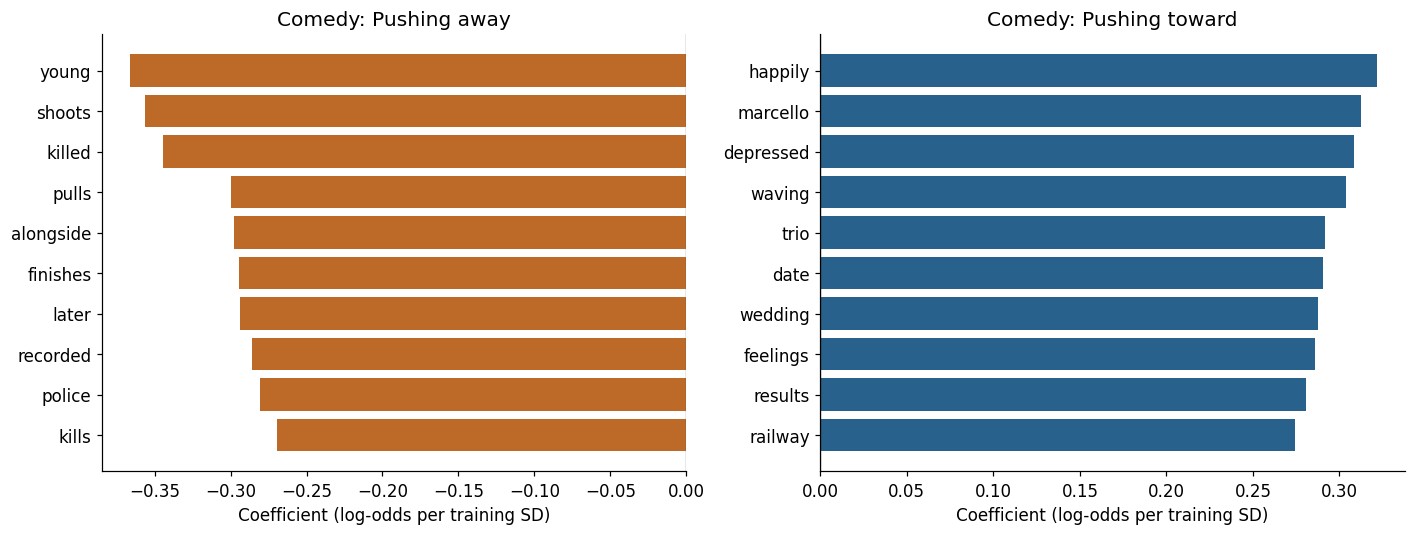

**Observed interpretation.** Comedy: strongest positive word is "happily" (+0.322); strongest negative is "young" (-0.366). Coefficients describe model tendencies, not how frequently those words occur.

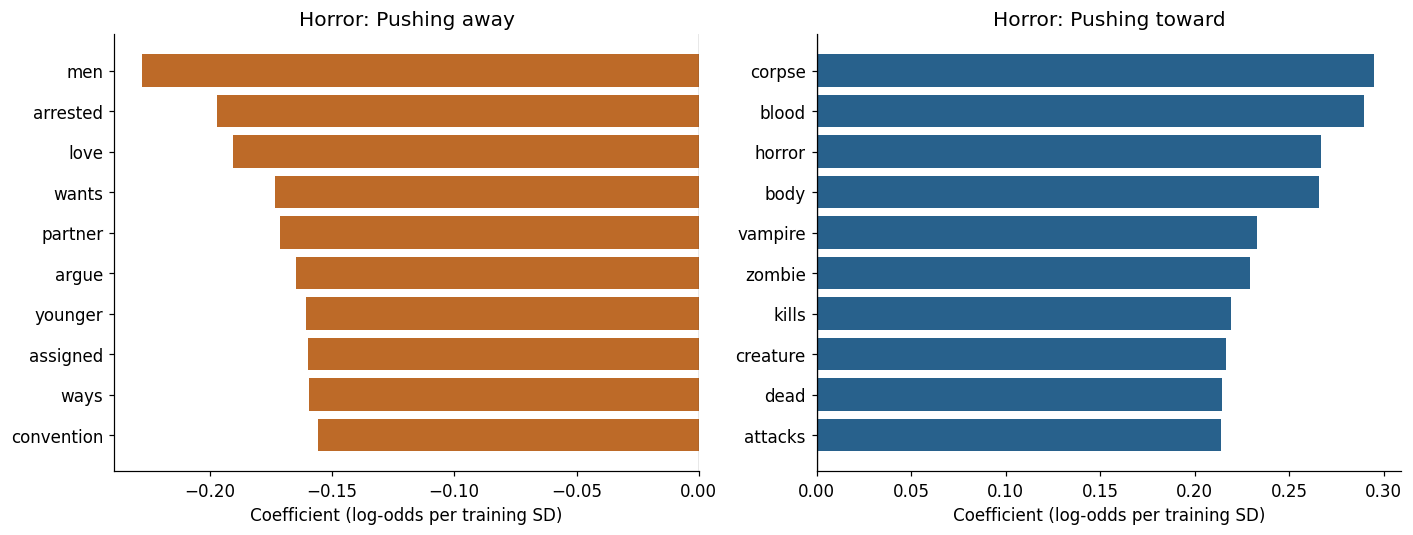

**Observed interpretation.** Horror: strongest positive word is "corpse" (+0.295); strongest negative is "men" (-0.228). Coefficients describe model tendencies, not how frequently those words occur.

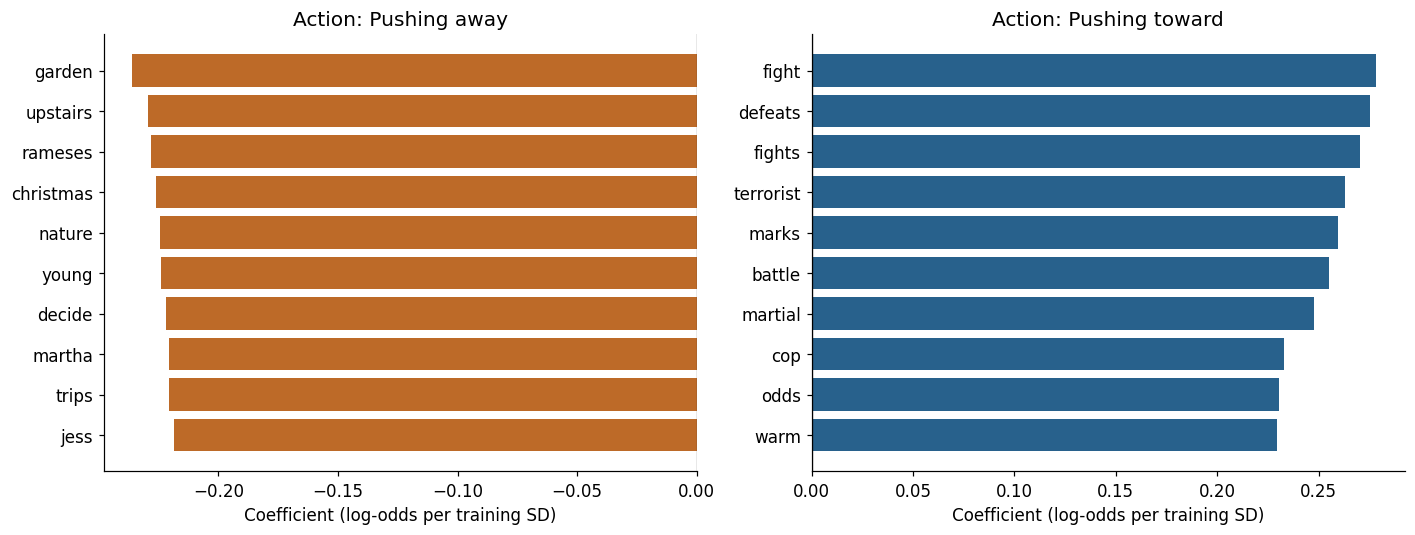

**Observed interpretation.** Action: strongest positive word is "fight" (+0.279); strongest negative is "garden" (-0.236). Coefficients describe model tendencies, not how frequently those words occur.

In [2]:
coefficient_tables={}
for genre,model in models.items():
    coef=model.coef_[0]
    positive=np.argsort(coef)[-10:][::-1]
    negative=np.argsort(coef)[:10]
    coefficient_tables[genre]=pd.DataFrame({'word':words,'coefficient':coef})
    fig,axes=plt.subplots(1,2,figsize=(13,5))
    for ax,idx,color,title in [(axes[0],negative,ORANGE,'Pushing away'),
                               (axes[1],positive,BLUE,'Pushing toward')]:
        ax.barh(words[idx][::-1],coef[idx][::-1],color=color)
        ax.axvline(0,color='#333333',lw=.8)
        ax.set(title=f'{genre}: {title}',xlabel='Coefficient (log-odds per training SD)')
    fig.tight_layout();plt.show()
    note(f'{genre}: strongest positive word is "{words[positive[0]]}" '
         f'({coef[positive[0]]:+.3f}); strongest negative is "{words[negative[0]]}" '
         f'({coef[negative[0]]:+.3f}). Coefficients describe model tendencies, not how frequently those words occur.')

**Interpretation.** A large coefficient can belong to a rarely used word. Coefficient magnitude alone does not tell us the average impact across actual test movies. Correlated terms, regularization and genre co-occurrence can also change the sign of a coefficient.

## 3. SHAP

**Decision.** Use SHAP LinearExplainer for Comedy over the entire held-out test set.

**Explanation.** Use the mean standardized training feature vector as an interventional background, which is sufficient for a linear model. Compute every test movie’s contribution, then show a mean-absolute-SHAP bar chart and a beeswarm of the same leading words. Contributions are in log-odds, not probability percentage points.

### SHAP assumptions
For this linear model, interventional SHAP is `coefficient × (feature value − training mean)`. Sparse inputs support the interventional option. This treats words independently even though real language contains correlated words; explanations describe the fitted model under that assumption.

The background mean is computed on training movies only. The bar plot summarizes magnitude and hides sign and variation. The beeswarm shows how contribution sign, frequency and standardized word value vary across individual movies. Colors show lower versus higher feature values, not whether an IMDB label is correct.

The bar chart displays the top 20 individual words. Unshown features are not summed into a single dominant bar; all 8,000 feature contributions are still computed and checked for every test row.

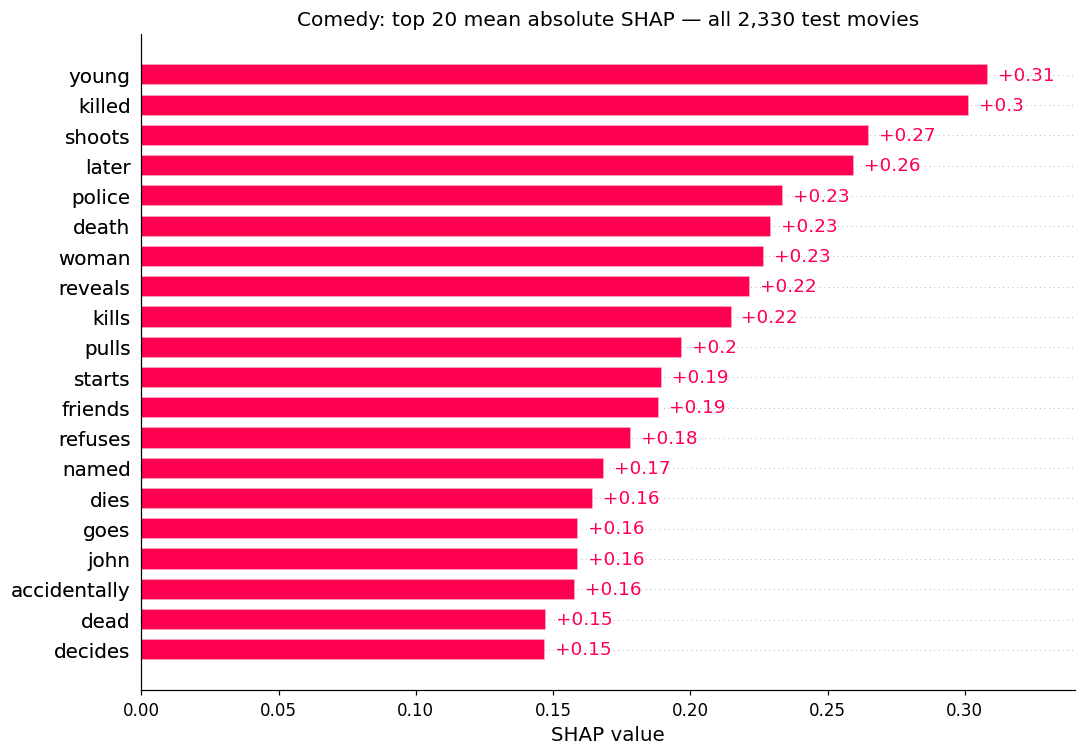

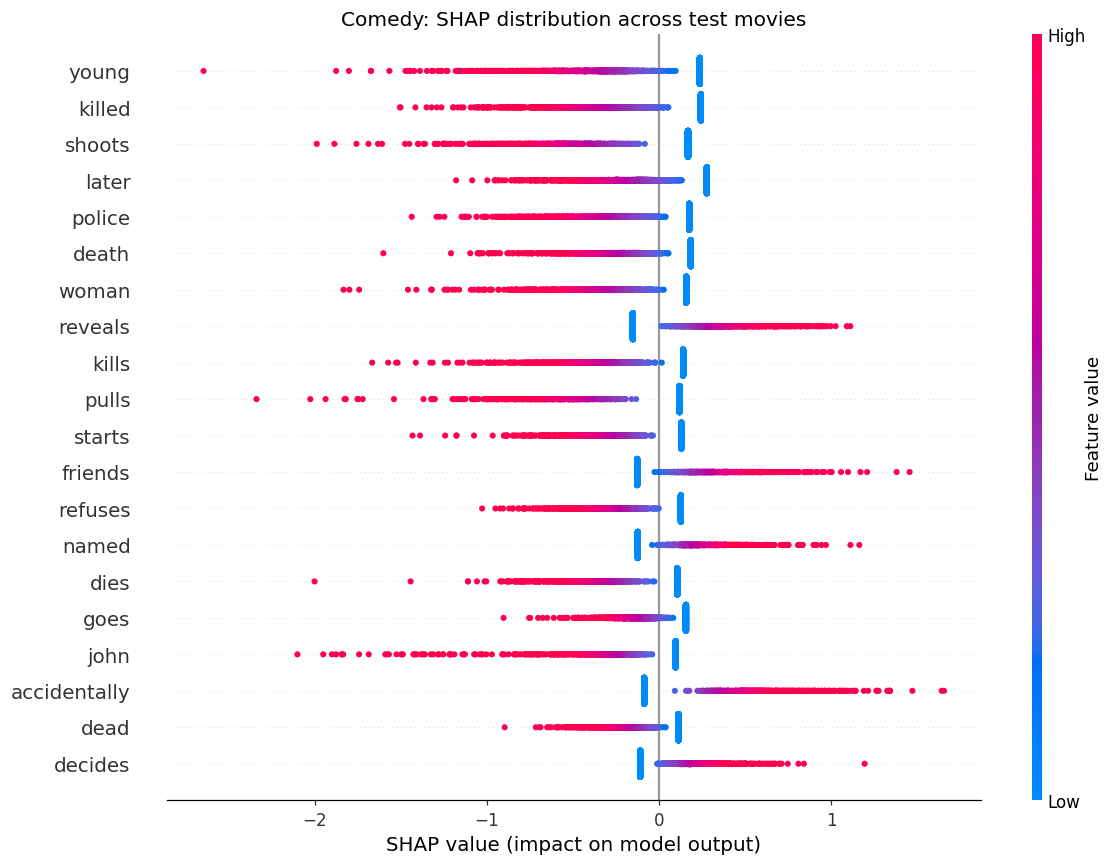

,word,coefficient,abs_coefficient_rank,mean_abs_shap,shap_rank,test_document_rate
7979,young,-0.3662,1,0.3084,1,0.3614
4012,killed,-0.3446,3,0.3017,2,0.4082
6521,shoots,-0.3565,2,0.2652,3,0.2094
4115,later,-0.2936,11,0.2597,4,0.5446
5416,police,-0.2808,18,0.2339,5,0.3309
1898,death,-0.2656,26,0.2294,6,0.3828
7901,woman,-0.2679,24,0.2268,7,0.3236
6026,reveals,0.2655,28,0.2216,8,0.2888
4018,kills,-0.2697,22,0.2150,9,0.2670
5636,pulls,-0.2997,8,0.1971,10,0.1399


**Observed interpretation.** The top-ten absolute-coefficient and mean-|SHAP| lists share 4 words. The largest average contribution belongs to "young". Additivity holds with maximum numerical error 4.26e-14 log-odds. Ranking differences reflect actual feature variation and occurrence rates as well as coefficient size.

In [3]:
import shap
EXPLAIN_GENRE='Comedy'
model=models[EXPLAIN_GENRE]
background=np.asarray(Xtrain.mean(axis=0)).reshape(1,-1)
masker=shap.maskers.Independent(background,max_samples=1)
explainer=shap.LinearExplainer(model,masker)
# Compute SHAP values for ALL test rows, retaining sparse model inputs until explanation.
explanation=explainer(Xtest)
shap_values=np.asarray(explanation.values)
assert shap_values.shape==Xtest.shape
base=np.asarray(explanation.base_values).reshape(-1)
if base.size==1:base=np.repeat(base,len(test))
logits=model.decision_function(Xtest)
max_additivity_error=float(np.max(np.abs(base+shap_values.sum(axis=1)-logits)))
assert np.allclose(base+shap_values.sum(axis=1),logits,atol=1e-6)
mean_abs=np.mean(np.abs(shap_values),axis=0)
ranking=np.argsort(mean_abs)[::-1]
top=ranking[:20]
mean_explanation=shap.Explanation(values=mean_abs[top],feature_names=words[top])
shap.plots.bar(mean_explanation,max_display=20,show=False)
plt.gcf().set_size_inches(10,7)
plt.title(f'{EXPLAIN_GENRE}: top 20 mean absolute SHAP — all {len(test):,} test movies')
plt.tight_layout();plt.show()
# Densify only the plotted columns, keeping full SHAP calculations for additivity and waterfalls.
beeswarm=shap.Explanation(values=shap_values[:,top],base_values=base,
    data=Xtest[:,top].toarray(),feature_names=words[top])
shap.plots.beeswarm(beeswarm,max_display=20,show=False,plot_size=(11,8))
plt.title(f'{EXPLAIN_GENRE}: SHAP distribution across test movies')
plt.tight_layout();plt.show()
coef_rank=pd.Series(np.abs(model.coef_[0])).rank(ascending=False,method='min').astype(int)
shap_rank=pd.Series(mean_abs).rank(ascending=False,method='min').astype(int)
comparison=pd.DataFrame({'word':words,'coefficient':model.coef_[0],
    'abs_coefficient_rank':coef_rank,'mean_abs_shap':mean_abs,'shap_rank':shap_rank,
    'test_document_rate':np.asarray((Xtest!=0).mean(axis=0)).ravel()})
display(comparison.iloc[top[:12]].round(4))
overlap=len(set(np.argsort(np.abs(model.coef_[0]))[-10:]) & set(ranking[:10]))
note(f'The top-ten absolute-coefficient and mean-|SHAP| lists share {overlap} words. '
     f'The largest average contribution belongs to "{words[ranking[0]]}". '
     f'Additivity holds with maximum numerical error {max_additivity_error:.2e} log-odds. '
     'Ranking differences reflect actual feature variation and occurrence rates as well as coefficient size.')
comparison.to_csv(WORK/'shap_vs_coefficients.csv',index=False)

**Interpretation.** The bar chart measures average contribution size; a word can rank highly while pushing in different directions for different movies. The beeswarm reveals that dispersion and direction, including effects of a word being absent relative to the training baseline. Correlated words make a causal reading inappropriate.

## 4. Individual predictions

**Decision.** Explain the most confident correct and most confident incorrect Comedy predictions.

**Explanation.** Choose examples mechanically from test outcomes: maximize probability assigned to the predicted class within correct cases and within errors. This shows both model success and failure without selecting a preferred story. For each, show true label, prediction, confidence and a SHAP waterfall. Read the synopsis before interpreting the mistake.

Out[4]: 766


### Confidently right: The Lord of the Rings: The Two Towers

IMDB label: **0**; prediction: **0**; P(Comedy): **0.0000**; predicted-class confidence: **100.00%**.

**Synopsis excerpt** (first 1,400 characters; the model used the full TF-IDF text):

The film begins with a flashback set to the first film, with Gandalf battling the Balrog on the Bridge of Khazad-dûm, but this time continues from Gandalf's perspective, with the scene continuing to follow both as they hurtle down below, fighting while in free-fall. The moment they hit the water of an underground lake, Frodo awakens from his dream and continues his journey with his trusted and loyal friend, Sam through the rocky region of Emyn Muil, where they become lost. They are then attacked by the ring-possessed Gollum wishing to retrieve "his precious" from the ones he thinks stole it from him. The Hobbits subdue and bind him with Sam's Elven rope given to him by the Elven elder Galadriel in Lórien. Sam distrusts Gollum and wishes to abandon him, but Frodo understands the burden of the creature and takes pity on him. In need of a guide, Frodo removes the rope from Gollum's neck and persuades him to lead them to the Black Gate of Mordor.In Rohan, the pack of Uruk-hai run across the grassy landscape with their captives Merry and Pippin. Aragorn, Legolas and Gimli are in pursuit, following three days of running, Legolas surmises the Hobbits are being taken to Isengard, where Saruman is marshaling his Uruk-hai forces to do the bidding of Sauron. In the kingdom of Rohan, home of the horse lords, King Théoden is mentally and physically weak due to the enchantments of his stewar

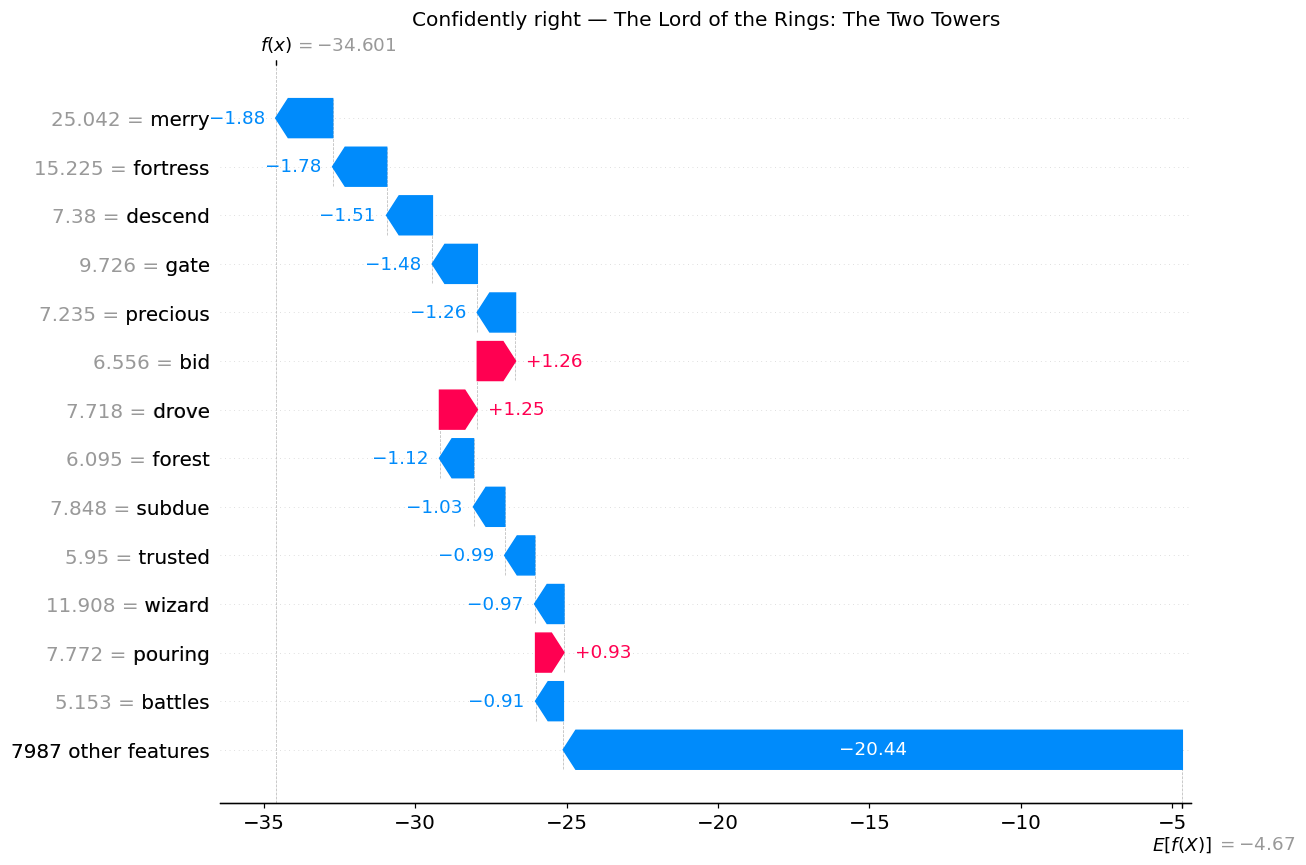

,word,shap_log_odds,standardized_tfidf
0,merry,-1.8791,25.0420
1,fortress,-1.7817,15.2247
2,descend,-1.5100,7.3804
3,gate,-1.4832,9.7264
4,precious,-1.2620,7.2346
5,bid,1.2598,6.5561


**Observed interpretation.** Baseline log-odds -4.670 plus SHAP contributions -29.932 gives -34.601; the sigmoid is 0.0000. The largest contributions identify the evidence the model relied on. They do not prove the IMDB label is incorrect.

### Most confidently wrong: Company

IMDB label: **1**; prediction: **0**; P(Comedy): **0.0000**; predicted-class confidence: **100.00%**.

**Synopsis excerpt** (first 1,400 characters; the model used the full TF-IDF text):

The story revolves around a young man named Chandu (Chandrakant Nagre) (played by Vivek Oberoi) joining the world of crime in the Mumbai underworld to "make it big" someday. Gradually he learns the tricks of the trade and increases the gang's earnings and profits. This leads to his affinity with Malik (Ajay Devgan), the leader of the gang. The film features one cold-blooded murder scene in which Malik and Chandu kill Saeed and his brother Anis in the rear seat of the car on a chilling rainy day. Thereafter Malik goes on a bloody rampage killing all his opponents, to take the reins of underworld in his hands. In this stage, Malik says a prominent dialogue "Sab ganda hai par dhanda hai yeh" (It's all dirty, but it's business).
His rival gang leader and colleague under Aslam's umbrella Sharma, who was in a meeting with police inspector Rathod, is killed off. Inspector Rathod, who once tortured and abused Chandu in jail in early days, is killed at Malik's permission. However, both come at loggerheads during the execution of a contract killing. Chandu stops the deliberate vehicle crash and falls from Malik's favor. The contract was from a politician who tries to use Malik's gang to eliminate a front-runner, a contender for Home Minister's post. The assassination (a staged truck-car collision) takes place in spite of Chandu's emotional misdemeanor since Malik, not relying on Chandu a

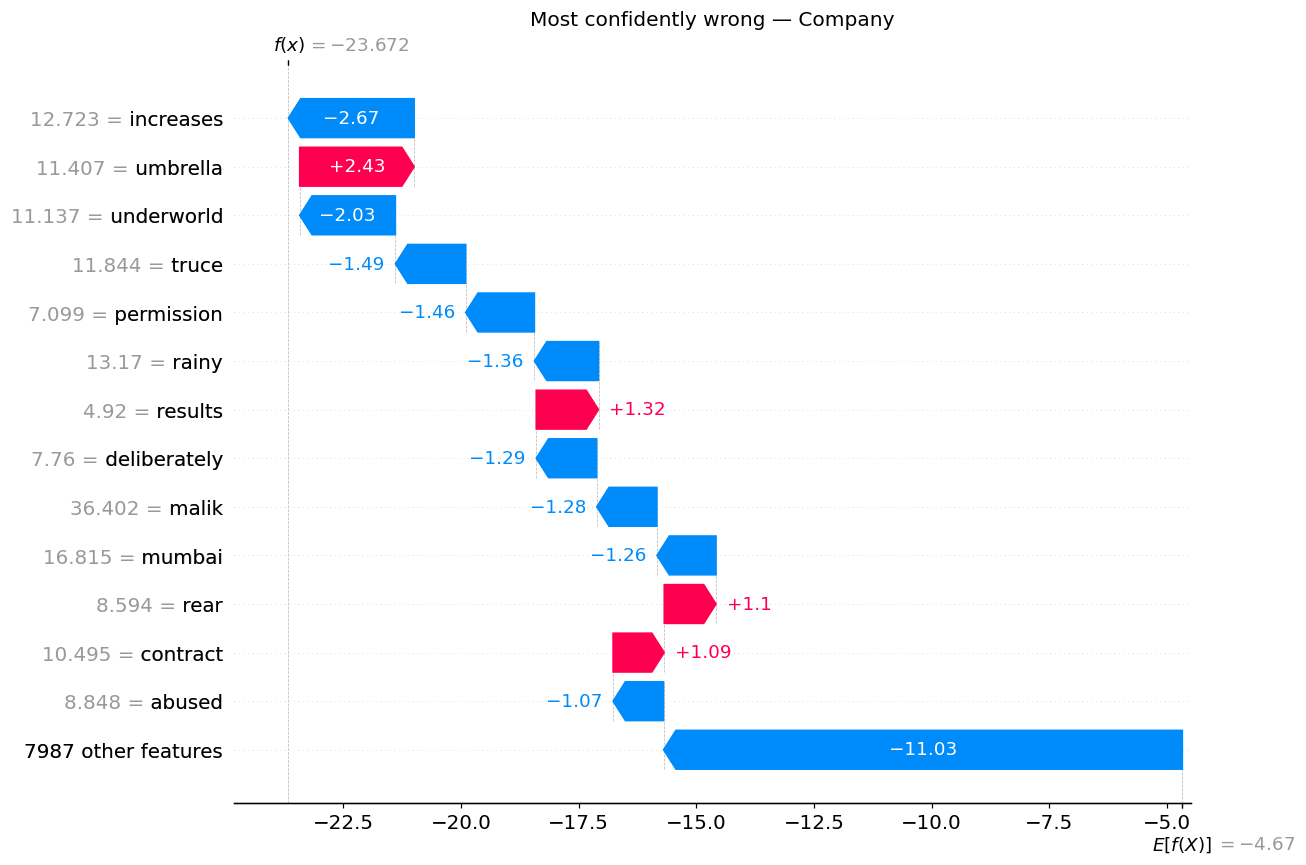

,word,shap_log_odds,standardized_tfidf
0,increases,-2.6745,12.7230
1,umbrella,2.4336,11.4067
2,underworld,-2.0346,11.1366
3,truce,-1.4926,11.8439
4,permission,-1.4621,7.0990
5,rainy,-1.3619,13.1696


**Observed interpretation.** Baseline log-odds -4.670 plus SHAP contributions -19.002 gives -23.672; the sigmoid is 0.0000. The largest contributions identify the evidence the model relied on. They do not prove the IMDB label is incorrect.

,imdb_id,primaryTitle,startYear,Comedy,Horror,Action
5471,tt0335013,The Company,2003.0,0,0,0
7118,tt1942831,Company,2011.0,1,0,0
10396,tt0296574,Company,2002.0,0,0,1


**Observed interpretation.** This exact plot appears under 3 different movie IDs with contradictory Comedy targets. The wrong case therefore requires a plot-to-movie alignment review; its confidence alone does not demonstrate a semantic failure on correctly matched data.

,case,test_row,imdb_id,title,true_label,predicted_label,p_comedy,predicted_class_confidence
0,Confidently right,57,tt0167261,The Lord of the Rings: The Two Towers,0,0,0.0,1.0
1,Most confidently wrong,1439,tt1942831,Company,1,0,0.0,1.0


In [4]:
probabilities=model.predict_proba(Xtest)[:,1]
pred=(probabilities>=.5).astype(int)
truth=test[EXPLAIN_GENRE].to_numpy()
confidence=np.maximum(probabilities,1-probabilities)
correct=np.flatnonzero(pred==truth)
wrong=np.flatnonzero(pred!=truth)
assert len(correct)>0 and len(wrong)>0, 'The assignment requires both a correct and an incorrect test example.'
case_indices={'Confidently right':int(correct[np.argmax(confidence[correct])]),
              'Most confidently wrong':int(wrong[np.argmax(confidence[wrong])])}
cases=[]
for label,i in case_indices.items():
    row=test.iloc[i]
    # Read all plot text in memory; bound only the displayed excerpt.
    full_plot=row.plot_synopsis
    cases.append({'case':label,'test_row':i,'imdb_id':row.imdb_id,'title':row.primaryTitle,
                  'true_label':int(truth[i]),'predicted_label':int(pred[i]),
                  'p_comedy':float(probabilities[i]),'predicted_class_confidence':float(confidence[i])})
    display(Markdown(f'### {label}: {row.primaryTitle}\n\n'
        f'IMDB label: **{truth[i]}**; prediction: **{pred[i]}**; '
        f'P(Comedy): **{probabilities[i]:.4f}**; predicted-class confidence: **{confidence[i]:.2%}**.\n\n'
        f'**Synopsis excerpt** (first 1,400 characters; the model used the full TF-IDF text):\n\n{full_plot[:1400]}'))
    local=shap.Explanation(values=shap_values[i],base_values=float(base[i]),
        data=Xtest[i].toarray().ravel(),feature_names=words)
    shap.plots.waterfall(local,max_display=14,show=False)
    plt.gcf().set_size_inches(12,8);plt.title(f'{label} — {row.primaryTitle}')
    plt.tight_layout();plt.show()
    leading=np.argsort(np.abs(shap_values[i]))[-6:][::-1]
    display(pd.DataFrame({'word':words[leading],'shap_log_odds':shap_values[i,leading],
                          'standardized_tfidf':Xtest[i,leading].toarray().ravel()}).round(4))
    note(f'Baseline log-odds {base[i]:+.3f} plus SHAP contributions '
         f'{shap_values[i].sum():+.3f} gives {logits[i]:+.3f}; '
         f'the sigmoid is {expit(logits[i]):.4f}. '
         'The largest contributions identify the evidence the model relied on. They do not prove the IMDB label is incorrect.')

    identical_plots=df.loc[df.plot_synopsis.eq(full_plot),['imdb_id','primaryTitle','startYear',*GENRES]]
    if len(identical_plots)>1 and identical_plots[EXPLAIN_GENRE].nunique()>1:
        display(identical_plots)
        note(f'This exact plot appears under {len(identical_plots)} different movie IDs with contradictory '
             f'{EXPLAIN_GENRE} targets. The wrong case therefore requires a plot-to-movie alignment review; '
             'its confidence alone does not demonstrate a semantic failure on correctly matched data.')

case_table=pd.DataFrame(cases)
display(case_table.round(4))
case_table.to_csv(WORK/'individual_prediction_cases.csv',index=False)
(WORK/'xai_metrics.json').write_text(json.dumps({'genre':EXPLAIN_GENRE,
    'all_test_rows_explained':len(test),'features':len(words),'additivity_max_error':max_additivity_error,
    'top10_coefficient_shap_overlap':overlap,'cases':cases},indent=2))

**Interpretation from the actual cases.** The mechanically selected correct case is *The Lord of the Rings: The Two Towers* (IMDB label 0, prediction 0). The mechanically selected incorrect case is *Company* (IMDB label 1, prediction 0). The waterfall plots and word-contribution tables show the evidence used by the supplied current TF-IDF model. Check the displayed identical-plot audit before interpreting an error as a semantic misunderstanding. SHAP explanations describe the classifier, rather than establish the true genre of a movie.

### Completion checks
The notebook restores all three TF-IDF models, plots 20 signed coefficients per genre, computes LinearExplainer values for the full test set, verifies log-odds additivity, and displays both a confident correct case and the most confident error. No model is tuned using these examples. Full teacher/student completion remains Notebook 2’s responsibility.